By MIQ

# Currency Prediction using LSTM

By help of https://finance.yahoo.com/markets/currencies/

In [ ]:
!pip install yfinance
!pip install scikit-learn

In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

In [ ]:
# Choose your currency pair
ticker = 'USDINR=X'

# Download data
data = yf.download(ticker, start='2020-01-01', end='2025-06-14')
data = data[['Close']]
data.dropna(inplace=True)
data.head()

[*********************100%***********************]  1 of 1 completed


Price,Close
Ticker,USDINR=X
Date,
2020-01-01,71.275803
2020-01-02,71.025002
2020-01-03,71.415001
2020-01-06,71.731003
2020-01-07,71.787003


In [ ]:
# Normalize the values between 0 and 1
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(data)

# Convert data to supervised format (sliding window)
def create_dataset(dataset, time_step=60):
    X, Y = [], []
    for i in range(len(dataset) - time_step - 1):
        a = dataset[i:(i + time_step), 0]
        X.append(a)
        Y.append(dataset[i + time_step, 0])
    return np.array(X), np.array(Y)

time_step = 60
X, y = create_dataset(scaled_data, time_step)
X = X.reshape(X.shape[0], X.shape[1], 1)

In [ ]:
model = Sequential()
model.add(LSTM(50, return_sequences=True, input_shape=(time_step, 1)))
model.add(LSTM(50))
model.add(Dense(1))
model.compile(optimizer='adam', loss='mean_squared_error')

# Train the model
model.fit(X, y, epochs=10, batch_size=64, verbose=1)

Epoch 1/10


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


22/22 ━━━━━━━━━━━━━━━━━━━━ 6s 103ms/step - loss: 0.1287
Epoch 2/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 63ms/step - loss: 0.0057
Epoch 3/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 3s 64ms/step - loss: 0.0018
Epoch 4/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 3s 68ms/step - loss: 9.4139e-04
Epoch 5/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 65ms/step - loss: 9.0831e-04
Epoch 6/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 3s 92ms/step - loss: 8.7831e-04
Epoch 7/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 78ms/step - loss: 8.8207e-04
Epoch 8/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 64ms/step - loss: 9.1676e-04
Epoch 9/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 3s 65ms/step - loss: 9.1895e-04
Epoch 10/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 64ms/step - loss: 9.0582e-04


In [ ]:
# Split test data
train_size = int(len(scaled_data) * 0.8)
test_data = scaled_data[train_size - time_step:]
X_test, y_test = create_dataset(test_data, time_step)
X_test = X_test.reshape(X_test.shape[0], X_test.shape[1], 1)

# Make predictions
predicted = model.predict(X_test)
predicted_prices = scaler.inverse_transform(predicted)
actual_prices = scaler.inverse_transform(y_test.reshape(-1, 1))

9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 144ms/step


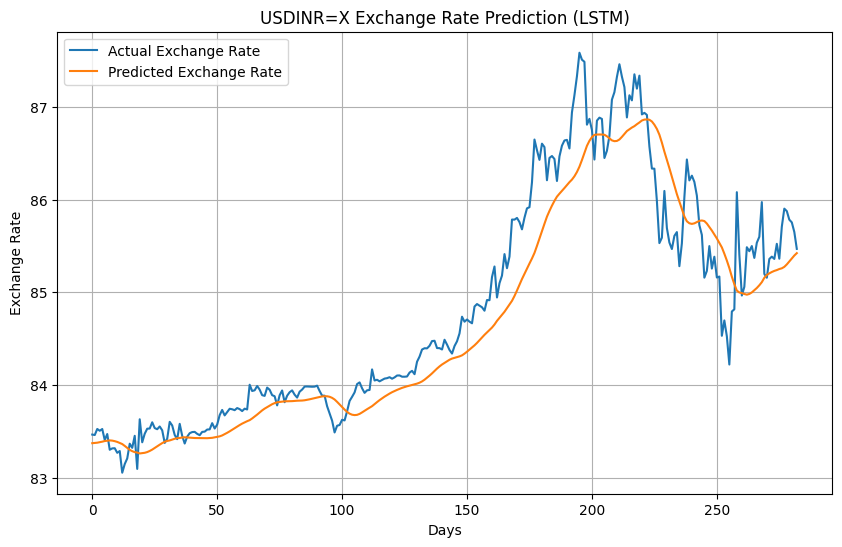

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(actual_prices, label='Actual Exchange Rate')
plt.plot(predicted_prices, label='Predicted Exchange Rate')
plt.title(f'{ticker} Exchange Rate Prediction (LSTM)')
plt.xlabel('Days')
plt.ylabel('Exchange Rate')
plt.legend()
plt.grid(True)
plt.show()

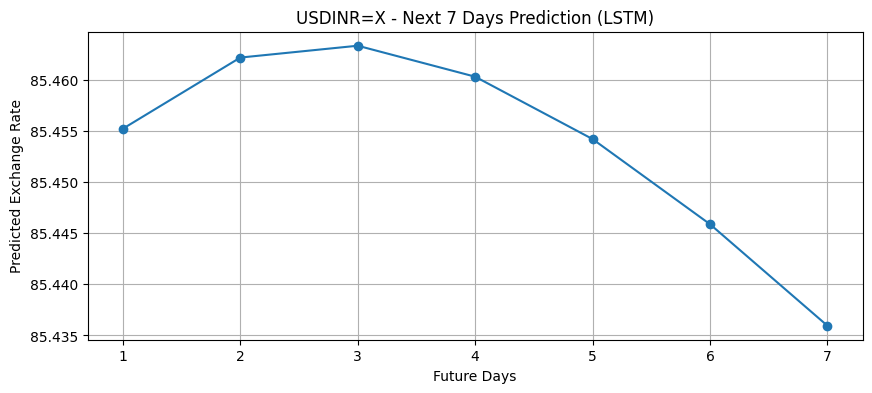

In [ ]:
# Predict next 7 future days
future_days = 7
future_input = scaled_data[-time_step:]  # Last 60 days
future_input = future_input.reshape(1, time_step, 1)

future_predictions = []

for _ in range(future_days):
    # Predict the next day
    next_pred = model.predict(future_input, verbose=0)[0][0]
    future_predictions.append([next_pred])  # Store the prediction


    future_input = np.append(future_input[:, 1:, :], [[[next_pred]]], axis=1)

# Convert predictions back to real exchange rate values
future_predictions = scaler.inverse_transform(future_predictions)

# Plot future predictions
plt.figure(figsize=(10, 4))
plt.plot(range(1, future_days + 1), future_predictions, marker='o')
plt.title(f'{ticker} - Next {future_days} Days Prediction (LSTM)')
plt.xlabel('Future Days')
plt.ylabel('Predicted Exchange Rate')
plt.grid(True)
plt.show()
